# Fig. 1(b,c): illustration of the response identity and bounds

A random five-state network. (b) Change of a state observable normalized by its linear response versus the perturbation strength, with the bounds of Eq. 9. (c) Change normalized by the standard deviation, with the resolution bound of Eq. 15.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join('..', 'lib')))
OUT = os.path.abspath(os.path.join('..', 'figures'))
os.makedirs(OUT, exist_ok=True)

import numpy as np
np.random.seed(2026)

## Model and helper functions

In [2]:
from ftMarkov import *
import matplotlib.pyplot as plt
import numpy as np

def generate_matrix(E,B,F):
    size = np.shape(E)[0]
    # Compute rates
    W = np.zeros((size, size))
    for i in range(size):
        for j in range(size):
            if i != j:
                W[i,j] = np.exp(-(B[i,j] - E[j] - F[i,j]/2))
    W = W - np.diag(W.sum(axis=0))
    return W

def generate_random_network(size, scale=12.0,seed=None):
    if seed is not None:
        np.random.seed(seed)
    """Generate random network parameters and transition rates"""
    # Generate parameters
    E = (np.random.rand(size)-0.5)*scale
    B = (np.random.rand(size, size)-0.5)*scale
    B = (B + B.T) / 2  # symmetric
    F = (np.random.rand(size,size)-0.5)*scale
    F = (F - F.T) / 2  # antisymmetric
    W = generate_matrix(E,B,F)
    return W, E, B, F

def compute_single_edge_response(W, E, B, F, m, n, eps_range, perturb_type,observable, response_fn,return_linear_response=False):
    """Compute response for a single edge over different perturbation strengths, using a user-specified response function"""
    # = MarkovNet(W)
    markov = MarkovNet( generate_matrix(E, B, F))
    #markov_small = W_small)
    original_pss = markov.pss
    # if postive:
    #     observable = np.random.randn(len(W))#np.exp(-8*np.random.randn(len(W)))#np.random.randn(len(W))
    # else:
    #     observable = #(np.random.randn(len(W)) - 0.5)
    original_obs = np.sum(observable * original_pss)
    original_obs_sq = np.sum((observable**2) * original_pss)
    original_variance = original_obs_sq - original_obs**2
    # First compute linear response (eps->0 limit)
    eps_small = 1e-4
    E_small, B_small, F_small = E.copy(), B.copy(), F.copy()
    
    if perturb_type == 'B':
        B_small[m,n] += eps_small
        B_small[n,m] += eps_small
    elif perturb_type == 'F':
        F_small[m,n] += eps_small
        F_small[n,m] -= eps_small
    elif perturb_type == 'E':
        E_small[m] += eps_small
    elif perturb_type == 'A':
        # For A perturbation, we directly perturb the A matrix element
        # A[i,j] = B[i,j] - E[j] - F[i,j]/2
        # So perturbing A[m,n] by eps_small is equivalent to perturbing B[m,n] by eps_small
        B_small[m,n] += eps_small
        
    W_small = generate_matrix(E_small, B_small, F_small)
    markov_small = MarkovNet(W_small)
    new_obs_small = np.sum(observable * markov_small.pss)
    linear_response = (new_obs_small - original_obs) / eps_small
    
    responses = []
    for eps in eps_range:
        E_new, B_new, F_new = E.copy(), B.copy(), F.copy()
        if perturb_type == 'B':
            B_new[m,n] += eps
            B_new[n,m] += eps
        elif perturb_type == 'F':
            F_new[m,n] += eps
            F_new[n,m] -= eps
        elif perturb_type == 'E':
            E_new[m] += eps
        elif perturb_type == 'A':
            # For A perturbation, we directly perturb the A matrix element
            # A[i,j] = B[i,j] - E[j] - F[i,j]/2
            # So perturbing A[m,n] by eps is equivalent to perturbing B[m,n] by eps
            B_new[m,n] += eps
        
        W_new = generate_matrix(E_new, B_new, F_new)
        markov_new = MarkovNet(W_new)
        new_pss = markov_new.pss
        new_obs = np.sum(observable * new_pss)
        # Calculate variance in perturbed case
        new_obs_sq = np.sum((observable**2) * new_pss)
        new_variance = new_obs_sq - new_obs**2
        
        # compute the response with the user-supplied function
        response = response_fn(original_obs, new_obs, eps,linear_response, original_variance, new_variance)
        responses.append(response)
    if return_linear_response:
        return responses, linear_response
    else:
        return responses


def plot_results(all_responses, eps_range, perturb_type):
    """Create plot of responses vs perturbation strength"""
    # Define colors for different perturbation types
    colors = {'B': '#0072B2', 'F': '#1f77b4', 'E': '#D55E00', 'A': '#009E73'}
    # Plot response for each network
    for i, responses in enumerate(all_responses):
        plt.plot(eps_range, responses, '-',
                alpha=0.2, color=colors[perturb_type])
    
    #plt.xlabel(f'Perturbation Strength ($\Delta {perturb_type}$)')
    #plt.ylabel(r'Current Response / Linear Response, $\frac{\Delta J_{mn}}{e^{\Delta F_e}-1}\left(\partial_{F_e}J_{mn}\right)^{-1}$')
    plt.grid(True, which="both", ls="-", alpha=0.2)
    return plt.gcf()


## Fig. 1(b)

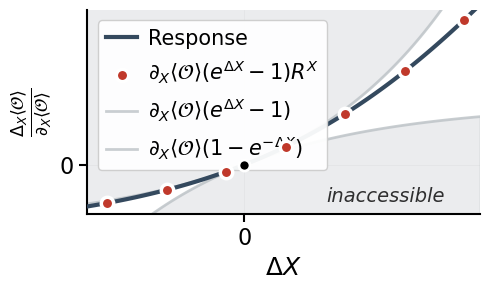

In [3]:
# Construct a specific 5-state circular network with additional 2-3 connection
SIZE = 5

# Create adjacency matrix for circular network (1-2-3-4-5-1) with randomly generated transition rates
W_adj = np.zeros((SIZE, SIZE))
# Set random seed for reproducibility
np.random.seed(42)
# Circular connections: 0-1-2-3-4-0 (using 0-based indexing)
W_adj[0, 1] = 1  # Connection exists
W_adj[1, 2] = 1  # Connection exists
W_adj[2, 3] = 1  # Connection exists
W_adj[3, 4] = 1  # Connection exists
W_adj[4, 0] = 1  # Connection exists
# Reverse connections
W_adj[1, 0] = 1  # Connection exists
W_adj[2, 1] = 1  # Connection exists
W_adj[3, 2] = 1  # Connection exists
W_adj[4, 3] = 1  # Connection exists
W_adj[0, 4] = 1  # Connection exists

# Create rate matrices with randomly generated exponential parameters
E = np.random.exponential(6.0, SIZE)  # Random energy levels
B = np.random.exponential(6.0, (SIZE, SIZE))  # Random barrier heights
F = np.random.exponential(6.5, (SIZE, SIZE))  # Random external forces

# Only keep rates where connections exist
B = B * W_adj
F = F * W_adj

# Generate the actual rate matrix
W = generate_matrix(E, B, F)

# Define perturbation parameters
eps_range = np.linspace(-1,1.5, 100)
m, n = 1,0  # Perturb edge 1-2 (0-1 in 0-based indexing)

# Define observable (you can modify this)
observable = np.array([1, 2, 0, 0, 0])  # Observable on state 1

# Define response function to compute the change in observable
def compute_response(W_adj, E, B, F, m, n, eps_values, perturb_type, observable):
    """
    Compute the response of an observable to perturbations of a specific edge.
    
    Parameters:
    - W_adj: adjacency matrix
    - E, B, F: energy, barrier, and force matrices
    - m, n: indices of the edge to perturb
    - eps_values: array of perturbation strengths
    - perturb_type: type of perturbation ('A', 'B', or 'F')
    - observable: observable vector
    
    Returns:
    - responses: array of response values
    - linear_response: linear response coefficient
    """
    # Compute original steady state
    W_original = generate_matrix(E, B, F)
    markov_original = MarkovNet( W_original)
    pi_original = markov_original.pss
    original_obs = np.dot(pi_original, observable)
    jss0 = markov_original.J(m,n)
    
    # Compute linear response (derivative at eps=0)
    if perturb_type == 'A':
        # Perturbation of energy difference
        E_pert = E.copy()
        E_pert[m] += 1e-8
        W_pert = generate_matrix(E_pert, B, F)
    elif perturb_type == 'B':
        # Perturbation of barrier height
        B_pert = B.copy()
        B_pert[m, n] += 1e-8
        B_pert[n, m] += 1e-8
        W_pert = generate_matrix(E, B_pert, F)
    elif perturb_type == 'F':
        # Perturbation of external force
        F_pert = F.copy()
        F_pert[m, n] += 1e-8
        F_pert[n, m] -= 1e-8
        W_pert = generate_matrix(E, B, F_pert)
    markov_pert = MarkovNet( W_pert)
    pi_pert = markov_pert.pss
    pert_obs = np.dot(pi_pert, observable)
    linear_response = (pert_obs - original_obs) / 1e-8
    
    # Compute responses for all perturbation strengths
    responses = []
    jss_list = []
    for eps in eps_values:
        if perturb_type == 'A':
            # Perturbation of energy difference
            E_new = E.copy()
            E_new[m] += eps
            W_new = generate_matrix(E_new, B, F)
        elif perturb_type == 'B':
            # Perturbation of barrier height
            B_new = B.copy()
            B_new[m, n] += eps
            B_new[n, m] += eps
            W_new = generate_matrix(E, B_new, F)
        elif perturb_type == 'F':
            # Perturbation of external force
            F_new = F.copy()
            F_new[m, n] += eps
            F_new[n, m] -= eps
            W_new = generate_matrix(E, B, F_new)
        
        markov_new = MarkovNet( W_new)
        pi_new = markov_new.pss
        new_obs = np.dot(pi_new, observable)
        responses.append(new_obs - original_obs)
        jss_list.append(markov_new.J(m,n)/jss0)
    
    return np.array(responses), linear_response, np.array(jss_list)

# Compute responses for B perturbation (barrier height perturbation)
perturb_type = 'B'
responses, linear_response, jss_list = compute_response(W_adj, E, B, F, m, n, eps_range, perturb_type, observable)

# Alternative: Ultra-minimalist schematic version
plt.figure(figsize=(5,3))

# Normalize data for cleaner presentation
norm_responses = responses / linear_response
norm_upper = (np.exp(eps_range)-1)
norm_lower = (1-np.exp(-eps_range))
norm_theory = (np.exp(eps_range)-1)*jss_list

# Define minimalist color palette
primary_color = '#34495E'    # Dark blue-gray
accent_color = '#C0392B'     # Muted red
bound_color = '#BDC3C7'      # Light gray

# Main response curve
plt.plot(eps_range, norm_responses, color=primary_color, linewidth=3, 
         label='Response', zorder=5)

# Theory prediction - very sparse points
indices = [5, 20, 35, 50, 65, 80, 95]  # Select specific points
plt.scatter(eps_range[indices], norm_theory[indices], 
           color=accent_color, s=80, marker='o', 
           edgecolors='white', linewidth=2.5,
           label=r'$\partial_X \langle \mathcal{O}\rangle(e^{\Delta X}-1)R^X$', zorder=6)

# Shaded regions only (no lines)
plt.fill_between(eps_range, norm_upper, 10, alpha=0.3, color=bound_color)
plt.fill_between(eps_range, norm_lower, -10, alpha=0.3, color=bound_color)

# Bound lines with labels
plt.plot(eps_range, norm_upper, '-', color=bound_color, linewidth=2, alpha=0.8,
         label=r'$\partial_X \langle \mathcal{O}\rangle(e^{\Delta X}-1)$')
plt.plot(eps_range, norm_lower, '-', color=bound_color, linewidth=2, alpha=0.8,
         label=r'$\partial_X \langle \mathcal{O}\rangle(1-e^{-\Delta X})$')

# Origin emphasis
# plt.axhline(y=0, color='black', linestyle='--',linewidth=1.5, alpha=0.2)
# plt.axvline(x=0, color='black', linestyle='--',linewidth=1.5, alpha=0.2)
plt.plot(0, 0, 'ko', markersize=8, markerfacecolor='black', 
         markeredgewidth=2, markeredgecolor='white', zorder=7)

# Minimalist axes
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

# Only show 0 on both axes
ax.set_xticks([0])
ax.set_xticklabels(['0'])
ax.set_yticks([0])
ax.set_yticklabels(['0'])



plt.xlabel(r'$\Delta X$', fontsize=18)
#plt.ylabel(r'$\Delta_X \langle \mathcal{O}\rangle/\partial_X \langle \mathcal{O}\rangle$', fontsize=18)
plt.ylabel(r'$\frac{\Delta_X \langle \mathcal{O}\rangle}{\partial_X \langle \mathcal{O}\rangle}$', fontsize=18)
# Tick parameters
plt.tick_params(axis='both', which='major', labelsize=16, length=6, width=1.5)

# Limits
plt.xlim(-1, 1.5)
plt.ylim(-0.8, 2.5)

# Subtle grid for reference
plt.grid(True, alpha=0.15, linestyle='-', linewidth=0.5)

# Detailed legend with all components
plt.legend(loc='upper left', fontsize=15, frameon=True, 
          handlelength=1.5, handletextpad=0.5, framealpha=0.95,
          fancybox=True, shadow=False)

# Add conceptual annotations
plt.text(0.9, -0.6, 'inaccessible', fontsize=14, ha='center', color='black',
         alpha=.8, style='italic')

plt.tight_layout()
plt.savefig(os.path.join(OUT, 'Fig1b_response_illustration.svg'))
plt.show()


## Fig. 1(c)

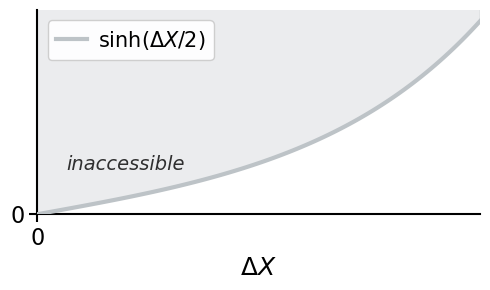

In [4]:
plt.figure(figsize=(5,3))

# Define minimalist color palette
primary_color = '#5D6D7E'    # Dark gray
bound_color = '#BDC3C7'  
# Create x range
x_range = np.linspace(0, 5, 100)

# Plot sinh(x/2)
plt.plot(x_range, np.abs(np.sinh(x_range/2)), color=bound_color, linewidth=3, 
         label=r'$\sinh(\Delta X/2)$', zorder=5)
plt.fill_between(x_range, np.abs(np.sinh(x_range/2)),10, alpha=0.3, color=bound_color)
# Origin emphasis
# plt.plot(0, 0, 'ko', markersize=8, markerfacecolor='black', 
#          markeredgewidth=2, markeredgecolor='white', zorder=7)

# Minimalist axes
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

# Only show 0 on both axes
ax.set_xticks([0])
ax.set_xticklabels(['0'])
ax.set_yticks([0])
ax.set_yticklabels(['0'])

# Clean labels
plt.xlabel(r'$\Delta X$', fontsize=18)
#plt.ylabel(r'$|\Delta_X \langle \mathcal{O}\rangle|/\sqrt{{\rm Var}(\mathcal{O})}$', fontsize=18)
#plt.ylabel(r'$\frac{|\Delta_X \langle \mathcal{O}\rangle|}{\sqrt{{\rm Var}(\mathcal{O})}}$', fontsize=18)
# Tick parameters
plt.tick_params(axis='both', which='major', labelsize=16, length=6, width=1.5)

# Limits
plt.xlim(-0.0, 5)
plt.ylim(-0.0, 6.4)

# Subtle grid for reference
plt.grid(True, alpha=0.15, linestyle='-', linewidth=0.5)
plt.text(1, 1.4, 'inaccessible', fontsize=14, ha='center', color='black',
         alpha=.8, style='italic')
# Legend
plt.legend(loc='upper left', fontsize=15, frameon=True, 
          handlelength=1.5, handletextpad=0.5, framealpha=0.95,
          fancybox=True, shadow=False)

plt.tight_layout()
plt.savefig(os.path.join(OUT, 'Fig1c_resolution_illustration.svg'))
plt.show()